In [1]:
import os
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print(os.getcwd())
print(os.path.exists("models/triage.joblib"))

BASE = "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data"
test = pd.read_csv(f"{BASE}/test.csv")
model = joblib.load("models/triage.joblib")

test["pred"] = model.predict(test["text"])
test["confidence"] = model.predict_proba(test["text"]).max(axis=1)
test["correct"] = test["category"] == test["pred"]

Path("docs/images").mkdir(parents=True, exist_ok=True)
print("Accuracy:", test["correct"].mean())
test.head()

c:\younus work\support-ticket-triage
True


c:\Users\pc\anaconda3\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfTransformer from version 1.9.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\pc\anaconda3\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfVectorizer from version 1.9.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\pc\anaconda3\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.9.1 when using version 1.9.0. This might lead to breaking c

Accuracy: 0.9


,text,category,pred,confidence,correct
0,How do I locate my card?,card_arrival,get_physical_card,0.093202,False
1,"I still have not received my new card, I order...",card_arrival,card_arrival,0.984277,True
2,I ordered a card but it has not arrived. Help ...,card_arrival,card_arrival,0.483083,True
3,Is there a way to know when my card will arrive?,card_arrival,card_arrival,0.775478,True
4,My card has not arrived yet.,card_arrival,card_arrival,0.765041,True


In [2]:
each_category_per = (test.groupby('category')['correct'].mean()*100).sort_values()
each_category_per

category
virtual_card_not_working                    67.5
balance_not_updated_after_bank_transfer     75.0
pending_transfer                            75.0
fiat_currency_support                       75.0
declined_transfer                           80.0
                                           ...  
transaction_charged_twice                  100.0
terminate_account                          100.0
passcode_forgotten                         100.0
apple_pay_or_google_pay                    100.0
verify_top_up                              100.0
Name: correct, Length: 77, dtype: float64

In [3]:
lowest_15_per = each_category_per.head(15)


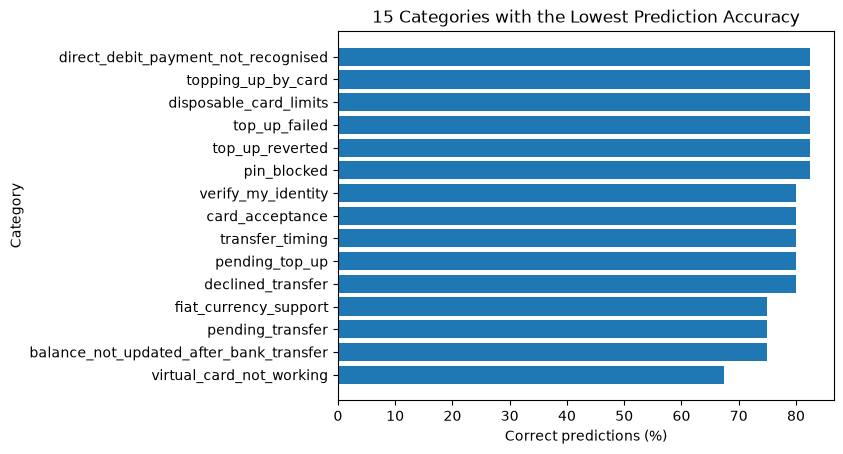

In [4]:
plt.barh(lowest_15_per.keys(),lowest_15_per.values)
plt.title('15 Categories with the Lowest Prediction Accuracy')
plt.xlabel('Correct predictions (%)')
plt.ylabel('Category')
plt.savefig('docs/images/worst_categories.png',dpi=150, bbox_inches="tight")

In [5]:
wrong_model = test[test.correct == False]
counts = wrong_model.groupby(["category", "pred"]).size().reset_index()

In [6]:

most10wrongpred = wrong_model[['category','pred']].value_counts().head(10)
print(most10wrongpred)

category                                 pred                              
virtual_card_not_working                 get_disposable_virtual_card           5
balance_not_updated_after_bank_transfer  transfer_not_received_by_recipient    5
verify_my_identity                       why_verify_identity                   5
card_arrival                             card_delivery_estimate                4
fiat_currency_support                    exchange_via_app                      4
pending_top_up                           top_up_failed                         4
card_acceptance                          card_not_working                      4
why_verify_identity                      unable_to_verify_identity             4
unable_to_verify_identity                verify_my_identity                    4
top_up_failed                            top_up_reverted                       4
Name: count, dtype: int64


In [7]:
lst = []
for i in most10wrongpred.index:
    lst.append(" -> ".join(i))
print(lst)

['virtual_card_not_working -> get_disposable_virtual_card', 'balance_not_updated_after_bank_transfer -> transfer_not_received_by_recipient', 'verify_my_identity -> why_verify_identity', 'card_arrival -> card_delivery_estimate', 'fiat_currency_support -> exchange_via_app', 'pending_top_up -> top_up_failed', 'card_acceptance -> card_not_working', 'why_verify_identity -> unable_to_verify_identity', 'unable_to_verify_identity -> verify_my_identity', 'top_up_failed -> top_up_reverted']


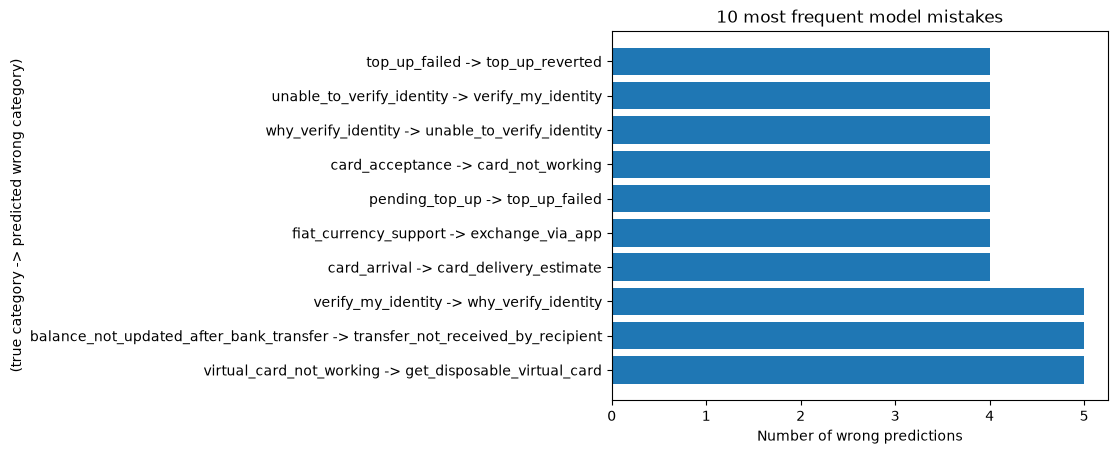

In [8]:
plt.barh(lst,most10wrongpred.values)
plt.title('10 most frequent model mistakes')
plt.xlabel('Number of wrong predictions')
plt.ylabel('(true category -> predicted wrong category)')
plt.savefig('docs/images/top_mistakes.png',dpi=150, bbox_inches="tight")

In [9]:
false_confident = (test[test.correct == False]['confidence'])*100
true_confident = (test[test.correct == True]['confidence'])*100

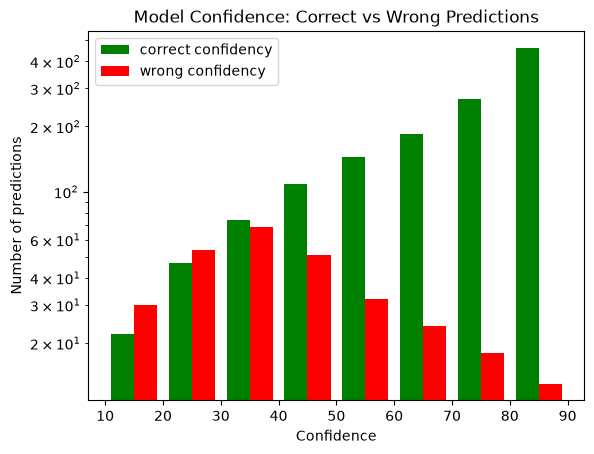

In [10]:
plt.hist([true_confident,false_confident],color=['green','red'],log=True,label=['correct confidency', 'wrong confidency'],bins=[10,20,30,40,50,60,70,80,90])
plt.legend()
plt.xlabel("Confidence")
plt.ylabel("Number of predictions")
plt.title('Model Confidence: Correct vs Wrong Predictions')
plt.savefig('docs/images/confidence.png',dpi=150, bbox_inches="tight")